In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

plt.rcParams["font.family"] = "Hiragino Sans"  # 日本語表示用（macOS）

PROJECT_DIR = Path.home() / "applied_programming_ii" / "07"
DATA_DIR = Path.home() / "applied_programming_ii" / "data"
FIGURE_DIR = PROJECT_DIR / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("作業フォルダ:", PROJECT_DIR)
print("人口データの有無:", (DATA_DIR / "population_japan.csv").exists())
print("ダムデータの有無:", (DATA_DIR / "dam_urayama_daily.csv").exists())

作業フォルダ: /Users/kkagawa/applied_programming_ii/07
人口データの有無: True
ダムデータの有無: True


In [4]:
population = pd.read_csv(DATA_DIR / "population_japan.csv")
population["population_10k"] = population["total_population_thousand"] / 10
t_obs = (population["year"] - 1920).values.astype(float)
y_obs = population["population_10k"].values
N0 = y_obs[0]
print(f"観測点: {len(t_obs)}，期間: {population['year'].min()}〜{population['year'].max()}年，初期人口: {N0:.1f} 万人")

観測点: 101，期間: 1920〜2020年，初期人口: 5596.3 万人


In [5]:
def logistic_rhs(t, N, r, K):
    """Logisticモデル dN/dt = r N (1 - N/K) の右辺．"""
    return r * N * (1 - N / K)


def simulate_logistic(theta, t_eval, N0):
    """パラメタ theta = (r, K) でLogisticモデルを解き，時刻 t_eval での N を返す．"""
    r, K = theta
    sol = solve_ivp(
        logistic_rhs,
        (t_eval[0], t_eval[-1]),
        [N0],
        t_eval=t_eval,
        args=(r, K),
        rtol=1e-06,
    )
    return sol.y[0]


def mean_squared_error(y_true, y_pred):
    """平均二乗誤差 (1/n) sum (y_true - y_pred)^2 を返す．"""
    return np.mean((y_true - y_pred) ** 2)

In [6]:
# 第5回の101×101格子で得た最良の組
theta_grid = (0.0275, 14800.0)
mse_grid = mean_squared_error(y_obs, simulate_logistic(theta_grid, t_obs, N0))
print(f"第5回の格子上の最良の組 (r, K) = {theta_grid}: MSE = {mse_grid:.1f} （RMSE = {np.sqrt(mse_grid):.1f} 万人）")

第5回の格子上の最良の組 (r, K) = (0.0275, 14800.0): MSE = 115105.5 （RMSE = 339.3 万人）


In [7]:
def residuals(theta, t_obs, y_obs, N0):
    return simulate_logistic(theta, t_obs, N0) - y_obs

In [8]:
theta_initial = [0.03, 13000.0]

In [9]:
result = least_squares(residuals, theta_initial, args=(t_obs, y_obs, N0))

In [11]:
r_hat, K_hat = result.x
print("停止条件を満たしたか:", result.success, " 状態:", result.message)
print(f"推定値: r = {r_hat:.5f} /年,  K = {K_hat:.1f} 万人")
print(f"目的関数（残差二乗和の半分）: {result.cost:.1f}")
print(f"RMSE: {np.sqrt(np.mean(result.fun ** 2)):.1f} 万人")
print(f"残差関数の評価回数: {result.nfev}")

停止条件を満たしたか: True  状態: `ftol` termination condition is satisfied.
推定値: r = 0.02759 /年,  K = 14753.8 万人
目的関数（残差二乗和の半分）: 5807180.6
RMSE: 339.1 万人
残差関数の評価回数: 7


In [12]:
mse_fitted = np.mean(result.fun ** 2)
improvement_percent = 100 * (mse_grid - mse_fitted) / mse_grid
print(f"格子探索の係数: r = {theta_grid[0]:.5f}, K = {theta_grid[1]:.1f}")
print(f"最適化後の係数: r = {r_hat:.5f}, K = {K_hat:.1f}")
print(f"格子探索の係数のMSE: {mse_grid:.1f}")
print(f"最適化後のMSE: {mse_fitted:.1f}")
print(f"MSEの減少率: {improvement_percent:.3f}%")

格子探索の係数: r = 0.02750, K = 14800.0
最適化後の係数: r = 0.02759, K = 14753.8
格子探索の係数のMSE: 115105.5
最適化後のMSE: 114993.7
MSEの減少率: 0.097%


In [13]:
initial_guesses = [
    [0.10, 10000.0],
    [0.05, 30000.0],
    [0.03, 13000.0],
    [0.01, 20000.0],
]

In [14]:
print(f"{'初期値 (r, K)':>22} {'推定 r':>10} {'推定 K':>10} {'cost':>12} {'評価回数':>8}")
for guess in initial_guesses:
    res = least_squares(residuals, guess, args=(t_obs, y_obs, N0))
    print(f"{str(guess):>22} {res.x[0]:10.5f} {res.x[1]:10.1f} {res.cost:12.1f} {res.nfev:8d}")

            初期値 (r, K)       推定 r       推定 K         cost     評価回数
        [0.1, 10000.0]    0.06375    10000.0  157753795.5       22
       [0.05, 30000.0]    0.02759    14753.8    5807180.6        6
       [0.03, 13000.0]    0.02759    14753.8    5807180.6        7
       [0.01, 20000.0]    0.02759    14753.8    5807180.6       10


In [15]:
guess = [0.5, 6000.0]
print(f"{'初期値 (r, K)':>22} {'推定 r':>10} {'推定 K':>10} {'cost':>12} {'評価回数':>8}")
res = least_squares(residuals, guess, args=(t_obs, y_obs, N0))
print(f"{str(guess):>22} {res.x[0]:10.5f} {res.x[1]:10.1f} {res.cost:12.1f} {res.nfev:8d}")

            初期値 (r, K)       推定 r       推定 K         cost     評価回数
         [0.5, 6000.0]    0.41007     6304.3 1011377852.1      200


In [16]:
lower_bounds = [0.0, 6000.0]       # r >= 0, K >= 6000 万人
upper_bounds = [1.0, 50000.0]      # r <= 1, K <= 50000 万人

result_bounded = least_squares(
    residuals, [0.5, 6000.0], args=(t_obs, y_obs, N0),
    bounds=(lower_bounds, upper_bounds),  # 追加箇所
)
print(f"範囲を指定した場合: r = {result_bounded.x[0]:.5f}, K = {result_bounded.x[1]:.1f}, cost = {result_bounded.cost:.1f}")

範囲を指定した場合: r = 0.02759, K = 14753.8, cost = 5807180.6


In [17]:
train_end = 1990
valid_start = train_end + 5
train_mask = population["year"] <= train_end
valid_mask = population["year"] >= valid_start

t_train, y_train = t_obs[train_mask], y_obs[train_mask]
t_valid, y_valid = t_obs[valid_mask], y_obs[valid_mask]

In [18]:
print(f"訓練期間: {len(t_train)} 点（1920〜{train_end}年）， 検証期間: {len(t_valid)} 点（{valid_start}〜2020年）")

訓練期間: 71 点（1920〜1990年）， 検証期間: 26 点（1995〜2020年）


In [19]:
result_train = least_squares(residuals, [0.03, 13000.0], args=(t_train, y_train, N0), bounds=(lower_bounds, upper_bounds))
r_train, K_train = result_train.x

In [20]:
print(f"訓練期間で推定: r = {r_train:.5f} /年,  K = {K_train:.1f} 万人")

訓練期間で推定: r = 0.01787 /年,  K = 25872.2 万人


In [21]:
# 推定したパラメタで全期間を計算する
y_fit_all = simulate_logistic(result_train.x, t_obs, N0)
rmse_train = np.sqrt(mean_squared_error(y_train, y_fit_all[train_mask]))
rmse_valid = np.sqrt(mean_squared_error(y_valid, y_fit_all[valid_mask]))

In [22]:
print(f"訓練期間の RMSE: {rmse_train:8.1f} 万人")
print(f"検証期間の RMSE: {rmse_valid:8.1f} 万人")
print(f"2020年の予測: {y_fit_all[-1]:.1f} 万人，観測: {y_obs[-1]:.1f} 万人")

訓練期間の RMSE:    141.0 万人
検証期間の RMSE:   2154.6 万人
2020年の予測: 16101.1 万人，観測: 12614.6 万人


In [23]:
years = population["year"].values
residual_all = y_fit_all - y_obs

In [24]:
dam = pd.read_csv(DATA_DIR / "dam_urayama_daily.csv", parse_dates=["date"])

In [25]:
year = 2019
dam_year = dam[dam["date"].dt.year == year].reset_index(drop=True)

In [26]:
SECONDS_PER_DAY = 24 * 60 * 60
LEVEL_MIN = 304.0

In [27]:
def m3s_to_1000m3_per_day(flow_m3s):
    """流量 [m^3/s] を [千m^3/日] に換算する．"""
    return flow_m3s * SECONDS_PER_DAY / 1000

In [28]:
t_dam = np.arange(len(dam_year), dtype=float)
qin_dam = m3s_to_1000m3_per_day(dam_year["inflow_m3s"].values)
qout_dam = m3s_to_1000m3_per_day(dam_year["outflow_m3s"].values)
h_dam = dam_year["water_level_m"].values

In [29]:
print(f"対象年: {year}年，水位の範囲: {h_dam.min():.2f} 〜 {h_dam.max():.2f} m")

対象年: 2019年，水位の範囲: 371.35 〜 391.99 m


In [30]:
def reservoir_rhs(t, V, t_data, qin_data, qout_data):
    """dV/dt = Q_in(t) - Q_out(t) の右辺．入力は観測値の線形補間．"""
    return np.interp(t, t_data, qin_data) - np.interp(t, t_data, qout_data)

In [31]:
def simulate_level(alpha, t_data, qin_data, qout_data, h_data):
    """傾き alpha で貯水量を計算し，貯水位に戻して返す．初期条件は初日の観測貯水位から決める．"""
    V0 = alpha * (h_data[0] - LEVEL_MIN)
    sol = solve_ivp(
        reservoir_rhs,
        (t_data[0], t_data[-1]),
        [V0],
        t_eval=t_data,
        args=(t_data, qin_data, qout_data),
        max_step=1.0,
    )
    return LEVEL_MIN + sol.y[0] / alpha

In [32]:
def residuals_level(theta, t_data, qin_data, qout_data, h_data):
    """傾き theta[0] における貯水位の残差（モデル - 観測）を返す．"""
    return simulate_level(theta[0], t_data, qin_data, qout_data, h_data) - h_data

In [33]:
alpha_assumed = 56000.0 / (393.3 - 304.0)
residual_assumed = residuals_level([alpha_assumed], t_dam, qin_dam, qout_dam, h_dam)
rmse_assumed = np.sqrt(np.mean(residual_assumed ** 2))

In [34]:
print(f"第6回の仮定 alpha = {alpha_assumed:.1f} 千m^3/m のとき，貯水位の RMSE = {rmse_assumed:.2f} m")

第6回の仮定 alpha = 627.1 千m^3/m のとき，貯水位の RMSE = 4.64 m


In [35]:
result_alpha = least_squares(residuals_level, [alpha_assumed], args=(t_dam, qin_dam, qout_dam, h_dam), bounds=([100.0], [5000.0]))
alpha_hat = result_alpha.x[0]
rmse_alpha = np.sqrt(np.mean(result_alpha.fun ** 2))

In [36]:
h_assumed = simulate_level(alpha_assumed, t_dam, qin_dam, qout_dam, h_dam)
h_fitted = simulate_level(alpha_hat, t_dam, qin_dam, qout_dam, h_dam)

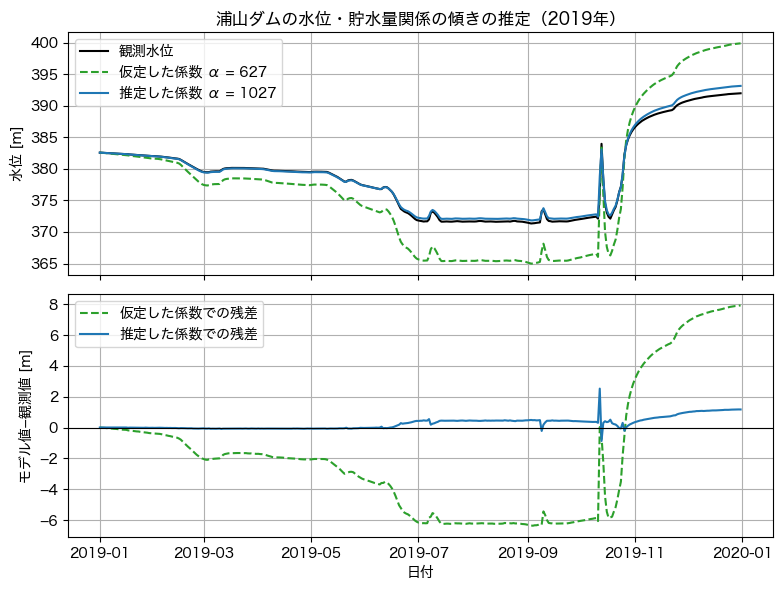

In [37]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(dam_year["date"], h_dam, color="black", label="観測水位")
axes[0].plot(dam_year["date"], h_assumed, color="tab:green", linestyle="--", label=f"仮定した係数 α = {alpha_assumed:.0f}")
axes[0].plot(dam_year["date"], h_fitted, color="tab:blue", label=f"推定した係数 α = {alpha_hat:.0f}")
axes[0].set_ylabel("水位 [m]")
axes[0].set_title(f"浦山ダムの水位・貯水量関係の傾きの推定（{year}年）")
axes[0].legend()
axes[1].plot(dam_year["date"], h_assumed - h_dam, color="tab:green", linestyle="--", label="仮定した係数での残差")
axes[1].plot(dam_year["date"], h_fitted - h_dam, color="tab:blue", label="推定した係数での残差")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("モデル値−観測値 [m]")
axes[1].set_xlabel("日付")
axes[1].legend()
for ax in axes:
    ax.grid(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"dam_alpha_estimation_{year}.png", dpi=150)
plt.show()

In [38]:
alpha_reference = alpha_hat

In [39]:
year = 2020
dam_year = dam[dam["date"].dt.year == year].reset_index(drop=True)
t_dam = np.arange(len(dam_year), dtype=float)  # 時刻 [日]（対象年の初日からの経過日数）
qin_dam = m3s_to_1000m3_per_day(dam_year["inflow_m3s"].values)  # 流入量 [千m^3/日]
qout_dam = m3s_to_1000m3_per_day(dam_year["outflow_m3s"].values)  # 放流量 [千m^3/日]
h_dam = dam_year["water_level_m"].values  # 観測水位 [m]

In [40]:
print(f"対象年: {year}年，水位の範囲: {h_dam.min():.2f} 〜 {h_dam.max():.2f} m")

対象年: 2020年，水位の範囲: 370.96 〜 393.07 m


In [41]:
h_reference = simulate_level(alpha_reference, t_dam, qin_dam, qout_dam, h_dam)
rmse_reference = np.sqrt(np.mean((h_reference - h_dam) ** 2))
print(f"2019年の係数を固定: alpha = {alpha_reference:.1f} 千m^3/m，RMSE = {rmse_reference:.3f} m")

2019年の係数を固定: alpha = 1027.0 千m^3/m，RMSE = 0.896 m


In [42]:
result_alpha = least_squares(
    residuals_level,
    [alpha_assumed],
    args=(t_dam, qin_dam, qout_dam, h_dam),
    bounds=([100.0], [5000.0]),
)
alpha_hat = result_alpha.x[0]
rmse_alpha = np.sqrt(np.mean(result_alpha.fun ** 2))
h_fitted = simulate_level(alpha_hat, t_dam, qin_dam, qout_dam, h_dam)
print("停止結果:", result_alpha.success, result_alpha.message)
print(f"対象年で再推定: alpha = {alpha_hat:.1f} 千m^3/m，RMSE = {rmse_alpha:.3f} m")

停止結果: True `xtol` termination condition is satisfied.
対象年で再推定: alpha = 1087.3 千m^3/m，RMSE = 0.320 m


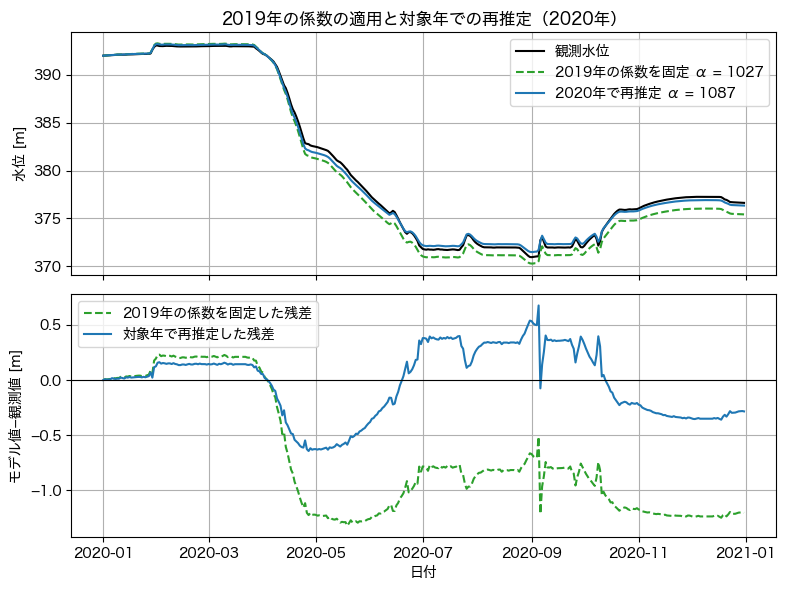

In [43]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(dam_year["date"], h_dam, color="black", label="観測水位")
axes[0].plot(dam_year["date"], h_reference, color="tab:green", linestyle="--", label=f"2019年の係数を固定 α = {alpha_reference:.0f}")
axes[0].plot(dam_year["date"], h_fitted, color="tab:blue", label=f"{year}年で再推定 α = {alpha_hat:.0f}")
axes[0].set_ylabel("水位 [m]")
axes[0].set_title(f"2019年の係数の適用と対象年での再推定（{year}年）")
axes[0].legend()
axes[1].plot(dam_year["date"], h_reference - h_dam, color="tab:green", linestyle="--", label="2019年の係数を固定した残差")
axes[1].plot(dam_year["date"], h_fitted - h_dam, color="tab:blue", label="対象年で再推定した残差")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("モデル値−観測値 [m]")
axes[1].set_xlabel("日付")
axes[1].legend()
for ax in axes:
    ax.grid(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"dam_alpha_transfer_{year}.png", dpi=150)
plt.show()

In [44]:
year = 2021
dam_year = dam[dam["date"].dt.year == year].reset_index(drop=True)
t_dam = np.arange(len(dam_year), dtype=float)  # 時刻 [日]（対象年の初日からの経過日数）
qin_dam = m3s_to_1000m3_per_day(dam_year["inflow_m3s"].values)  # 流入量 [千m^3/日]
qout_dam = m3s_to_1000m3_per_day(dam_year["outflow_m3s"].values)  # 放流量 [千m^3/日]
h_dam = dam_year["water_level_m"].values  # 観測水位 [m]
print(f"対象年: {year}年，水位の範囲: {h_dam.min():.2f} 〜 {h_dam.max():.2f} m")

対象年: 2021年，水位の範囲: 371.69 〜 376.62 m


In [46]:
h_reference = simulate_level(alpha_reference, t_dam, qin_dam, qout_dam, h_dam)
rmse_reference = np.sqrt(np.mean((h_reference - h_dam) ** 2))
print(f"2019年の係数を固定: alpha = {alpha_reference:.1f} 千m^3/m，RMSE = {rmse_reference:.3f} m")

2019年の係数を固定: alpha = 1027.0 千m^3/m，RMSE = 0.265 m


In [47]:
result_alpha = least_squares(
    residuals_level,
    [alpha_assumed],
    args=(t_dam, qin_dam, qout_dam, h_dam),
    bounds=([100.0], [5000.0]),
)
alpha_hat = result_alpha.x[0]
rmse_alpha = np.sqrt(np.mean(result_alpha.fun ** 2))
h_fitted = simulate_level(alpha_hat, t_dam, qin_dam, qout_dam, h_dam)
print("停止結果:", result_alpha.success, result_alpha.message)
print(f"対象年で再推定: alpha = {alpha_hat:.1f} 千m^3/m，RMSE = {rmse_alpha:.3f} m")

停止結果: True `ftol` termination condition is satisfied.
対象年で再推定: alpha = 939.8 千m^3/m，RMSE = 0.027 m


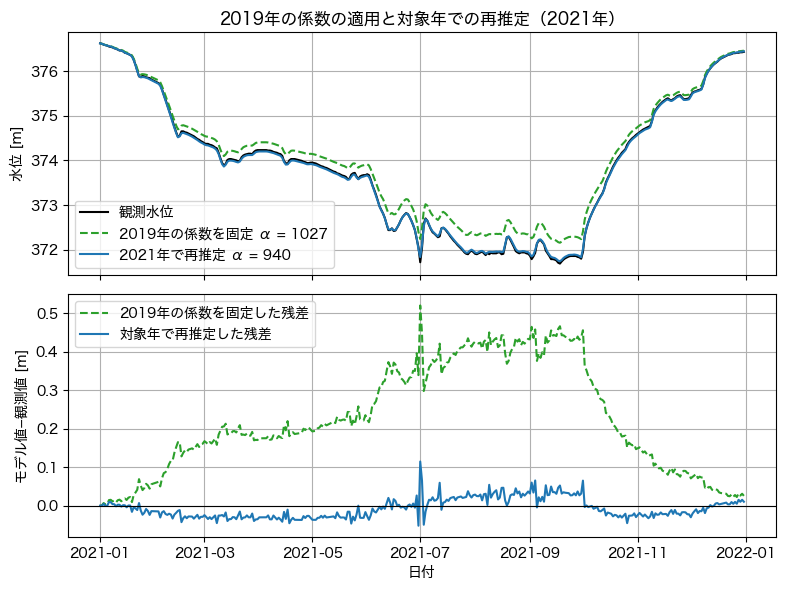

In [48]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(dam_year["date"], h_dam, color="black", label="観測水位")
axes[0].plot(dam_year["date"], h_reference, color="tab:green", linestyle="--", label=f"2019年の係数を固定 α = {alpha_reference:.0f}")
axes[0].plot(dam_year["date"], h_fitted, color="tab:blue", label=f"{year}年で再推定 α = {alpha_hat:.0f}")
axes[0].set_ylabel("水位 [m]")
axes[0].set_title(f"2019年の係数の適用と対象年での再推定（{year}年）")
axes[0].legend()
axes[1].plot(dam_year["date"], h_reference - h_dam, color="tab:green", linestyle="--", label="2019年の係数を固定した残差")
axes[1].plot(dam_year["date"], h_fitted - h_dam, color="tab:blue", label="対象年で再推定した残差")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("モデル値−観測値 [m]")
axes[1].set_xlabel("日付")
axes[1].legend()
for ax in axes:
    ax.grid(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"dam_alpha_transfer_{year}.png", dpi=150)
plt.show()

# 課題1

In [49]:
train_end = 1980
valid_start = train_end + 5
train_mask = population["year"] <= train_end
valid_mask = population["year"] >= valid_start

t_train, y_train = t_obs[train_mask], y_obs[train_mask]
t_valid, y_valid = t_obs[valid_mask], y_obs[valid_mask]

In [50]:
print(f"訓練期間: {len(t_train)} 点（1920〜{train_end}年）， 検証期間: {len(t_valid)} 点（{valid_start}〜2020年）")

訓練期間: 61 点（1920〜1980年）， 検証期間: 36 点（1985〜2020年）


In [51]:
result_train = least_squares(residuals, [0.03, 13000.0], args=(t_train, y_train, N0), bounds=(lower_bounds, upper_bounds))
r_train, K_train = result_train.x

In [52]:
print(f"訓練期間で推定: r = {r_train:.5f} /年,  K = {K_train:.1f} 万人")
print("停止結果:", result_train.success, result_train.message)

訓練期間で推定: r = 0.01500 /年,  K = 48065.8 万人
停止結果: True `ftol` termination condition is satisfied.


In [53]:
# 推定したパラメタで全期間を計算する
y_fit_all = simulate_logistic(result_train.x, t_obs, N0)
rmse_train = np.sqrt(mean_squared_error(y_train, y_fit_all[train_mask]))
rmse_valid = np.sqrt(mean_squared_error(y_valid, y_fit_all[valid_mask]))

In [54]:
print(f"訓練期間のRMSE: {rmse_train:8.1f} 万人")
print(f"検証期間のRMSE: {rmse_valid:8.1f} 万人")
print(f"2020年の予測: {y_fit_all[-1]:.1f} 万人，観測: {y_obs[-1]:.1f} 万人")

訓練期間のRMSE:    115.6 万人
検証期間のRMSE:   2851.2 万人
2020年の予測: 17843.8 万人，観測: 12614.6 万人


In [55]:
initial_guesses = [
    [0.10, 10000.0],
    [0.05, 30000.0],
    [0.03, 13000.0],
    [0.01, 20000.0],
]

print(f"{'初期値 (r, K)':>22} {'推定 r':>10} {'推定 K':>10} {'cost':>12} {'評価回数':>8}")
for guess in initial_guesses:
    res = least_squares(
        residuals, guess,
        args=(t_train, y_train, N0),
        bounds=(lower_bounds, upper_bounds),
    )
    print(f"{str(guess):>22} {res.x[0]:10.5f} {res.x[1]:10.1f} {res.cost:12.1f} {res.nfev:8d}")
    print("停止結果:", res.success, res.message)

            初期値 (r, K)       推定 r       推定 K         cost     評価回数
        [0.1, 10000.0]    0.01500    48065.8     407449.5       31
停止結果: True `ftol` termination condition is satisfied.
       [0.05, 30000.0]    0.01500    48065.8     407449.5       25
停止結果: True `ftol` termination condition is satisfied.
       [0.03, 13000.0]    0.01500    48065.8     407449.5       27
停止結果: True `ftol` termination condition is satisfied.
       [0.01, 20000.0]    0.01500    48065.8     407449.5       22
停止結果: True `ftol` termination condition is satisfied.


In [56]:
years = population["year"].values
residual_all = y_fit_all - y_obs

In [57]:
print(f"Logisticモデルの残差の範囲: {residual_all.min():.1f} 〜 {residual_all.max():.1f} 万人")

Logisticモデルの残差の範囲: -175.0 〜 5229.2 万人


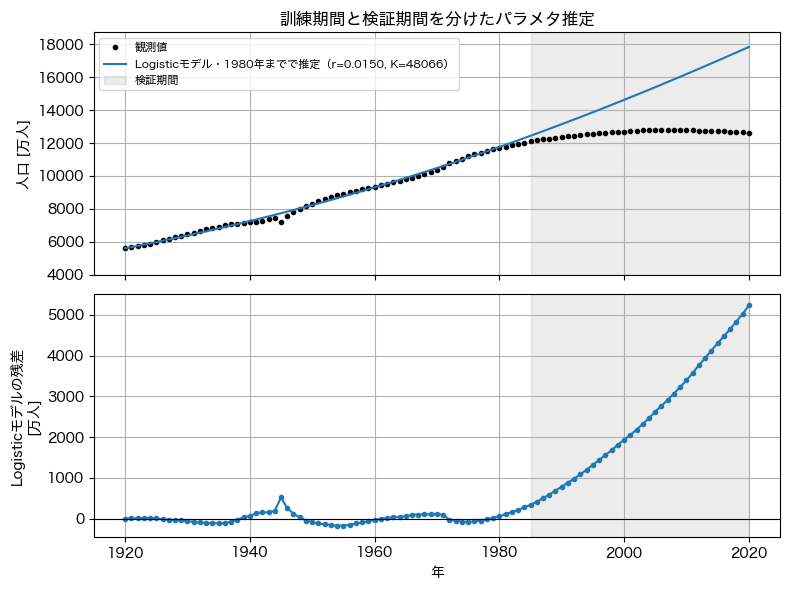

In [58]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

axes[0].plot(years, y_obs, color="black", marker="o", markersize=3, linestyle="none", label="観測値")
axes[0].plot(years, y_fit_all, color="tab:blue", label=f"Logisticモデル・{train_end}年までで推定（r={r_train:.4f}, K={K_train:.0f}）")
axes[0].axvspan(valid_start, 2020, color="gray", alpha=0.15, label="検証期間")
axes[0].set_ylabel("人口 [万人]")
axes[0].set_ylim(4000, 1.05 * max(y_obs.max(), y_fit_all.max()))
axes[0].set_title("訓練期間と検証期間を分けたパラメタ推定")
axes[0].legend(fontsize=8)

axes[1].plot(years, residual_all, color="tab:blue", marker="o", markersize=3)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].axvspan(valid_start, 2020, color="gray", alpha=0.15)
axes[1].set_ylabel("Logisticモデルの残差\n[万人]")

axes[1].set_xlabel("年")

for ax in axes:
    ax.grid(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"population_fit_{train_end}.png", dpi=150)
plt.show()

# 課題2

In [59]:
year = 2019
dam_year = dam[dam["date"].dt.year == year].reset_index(drop=True)
t_dam = np.arange(len(dam_year), dtype=float)  # 時刻 [日]（対象年の初日からの経過日数）
qin_dam = m3s_to_1000m3_per_day(dam_year["inflow_m3s"].values)  # 流入量 [千m^3/日]
qout_dam = m3s_to_1000m3_per_day(dam_year["outflow_m3s"].values)  # 放流量 [千m^3/日]
h_dam = dam_year["water_level_m"].values  # 観測水位 [m]

In [60]:
train_mask = dam_year["date"] <= "2019-06-30"
valid_mask = dam_year["date"] >= "2019-07-01"
t_train = t_dam[train_mask]
qin_train = qin_dam[train_mask]
qout_train = qout_dam[train_mask]
h_train = h_dam[train_mask]

In [61]:
alpha_assumed = 56000.0 / (393.3 - 304.0)
result_alpha_train = least_squares(
    residuals_level, [alpha_assumed],
    args=(t_train, qin_train, qout_train, h_train),
    bounds=([100.0], [5000.0]),
)
alpha_train = result_alpha_train.x[0]

In [62]:
h_fit_all = simulate_level(alpha_train, t_dam, qin_dam, qout_dam, h_dam)
residual_dam = h_fit_all - h_dam
rmse_train = np.sqrt(np.mean(residual_dam[train_mask] ** 2))
rmse_valid = np.sqrt(np.mean(residual_dam[valid_mask] ** 2))

In [63]:
print(f"訓練期間: 2019年1〜6月，{len(t_train)} 点")
print(f"検証期間: 2019年7〜12月，{len(t_dam[valid_mask])} 点")
print("停止結果:", result_alpha_train.success, result_alpha_train.message)
print(f"前半で推定した係数: alpha = {alpha_train:.1f} 千m^3/m")
print(f"訓練期間のRMSE: {rmse_train:.3f} m")
print(f"検証期間のRMSE: {rmse_valid:.3f} m")

訓練期間: 2019年1〜6月，181 点
検証期間: 2019年7〜12月，184 点
停止結果: True `ftol` termination condition is satisfied.
前半で推定した係数: alpha = 1022.4 千m^3/m
訓練期間のRMSE: 0.093 m
検証期間のRMSE: 0.659 m


In [64]:
valid_dates = dam_year["date"][valid_mask]
valid_start = valid_dates.min()
valid_end = valid_dates.max()

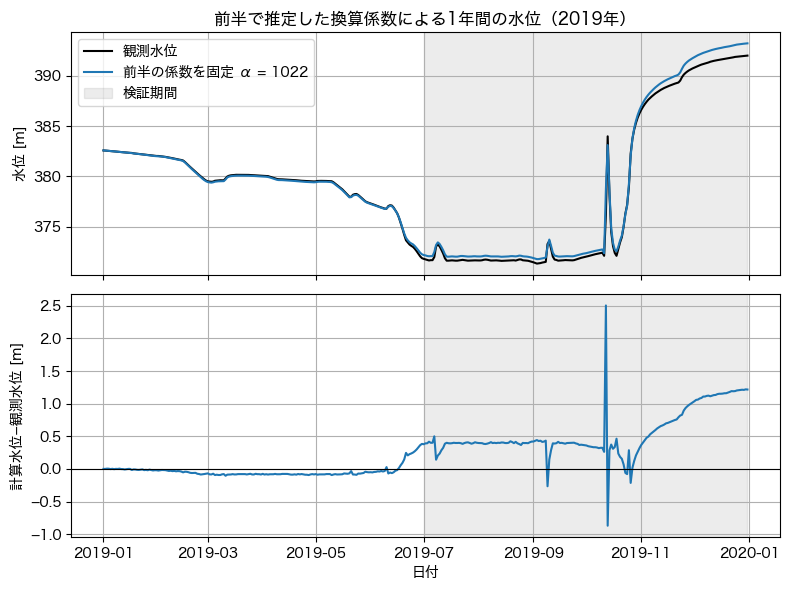

In [65]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(dam_year["date"], h_dam, color="black", label="観測水位")
axes[0].plot(dam_year["date"], h_fit_all, color="tab:blue", label=f"前半の係数を固定 α = {alpha_train:.0f}")
axes[0].axvspan(valid_start, valid_end, color="gray", alpha=0.15, label="検証期間")
axes[0].set_ylabel("水位 [m]")
axes[0].set_title("前半で推定した換算係数による1年間の水位（2019年）")
axes[0].legend()
axes[1].plot(dam_year["date"], residual_dam, color="tab:blue")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].axvspan(valid_start, valid_end, color="gray", alpha=0.15)
axes[1].set_ylabel("計算水位−観測水位 [m]")
axes[1].set_xlabel("日付")
for ax in axes:
    ax.grid(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "dam_halfyear_validation_2019.png", dpi=150)
plt.show()

# 発展課題

In [67]:
year = 2019
dam_year = dam[dam["date"].dt.year == year].reset_index(drop=True)
t_dam = np.arange(len(dam_year), dtype=float)  # 時刻 [日]（対象年の初日からの経過日数）
qin_dam = m3s_to_1000m3_per_day(dam_year["inflow_m3s"].values)  # 流入量 [千m^3/日]
qout_dam = m3s_to_1000m3_per_day(dam_year["outflow_m3s"].values)  # 放流量 [千m^3/日]
h_dam = dam_year["water_level_m"].values  # 観測水位 [m]

H_REF = 393.3 - LEVEL_MIN
V_REF = 56000.0

In [68]:
def simulate_level_power(power, t_data, qin_data, qout_data, h_data):
    V0 = V_REF * ((h_data[0] - LEVEL_MIN) / H_REF) ** (1 / power)
    sol = solve_ivp(
        reservoir_rhs, (t_data[0], t_data[-1]), [V0],
        t_eval=t_data, args=(t_data, qin_data, qout_data), max_step=1.0,
    )
    return LEVEL_MIN + H_REF * (sol.y[0] / V_REF) ** power

def residuals_level_power(theta, t_data, qin_data, qout_data, h_data):
    return simulate_level_power(theta[0], t_data, qin_data, qout_data, h_data) - h_data

In [69]:
result_power = least_squares(
    residuals_level_power, [0.5],
    args=(t_dam, qin_dam, qout_dam, h_dam),
    bounds=([1 / 3], [1.0]),
)
power_hat = result_power.x[0]
rmse_power = np.sqrt(np.mean(result_power.fun ** 2))
print("停止結果:", result_power.success, result_power.message)
print(f"推定した指数 p = {power_hat:.4f}，RMSE = {rmse_power:.3f} m")

停止結果: True `ftol` termination condition is satisfied.
推定した指数 p = 0.5262，RMSE = 0.190 m


In [70]:
h_linear = simulate_level(alpha_reference, t_dam, qin_dam, qout_dam, h_dam)
h_power = simulate_level_power(power_hat, t_dam, qin_dam, qout_dam, h_dam)

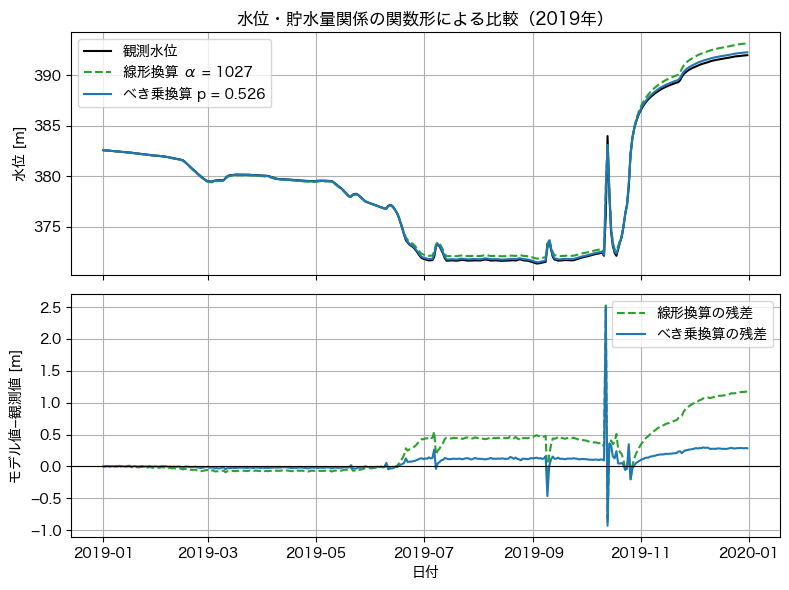

In [71]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(dam_year["date"], h_dam, color="black", label="観測水位")
axes[0].plot(dam_year["date"], h_linear, color="tab:green", linestyle="--", label=f"線形換算 α = {alpha_reference:.0f}")
axes[0].plot(dam_year["date"], h_power, color="tab:blue", label=f"べき乗換算 p = {power_hat:.3f}")
axes[0].set_ylabel("水位 [m]")
axes[0].set_title(f"水位・貯水量関係の関数形による比較（{year}年）")
axes[0].legend()
axes[1].plot(dam_year["date"], h_linear - h_dam, color="tab:green", linestyle="--", label="線形換算の残差")
axes[1].plot(dam_year["date"], h_power - h_dam, color="tab:blue", label="べき乗換算の残差")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("モデル値−観測値 [m]")
axes[1].set_xlabel("日付")
axes[1].legend()
for ax in axes:
    ax.grid(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "dam_power_estimation_2019.png", dpi=150)
plt.show()